# 1. Завантаження данний

In [36]:
from google.colab import files
uploaded = files.upload()

Saving infectious_cases.csv to infectious_cases (1).csv


##Результат
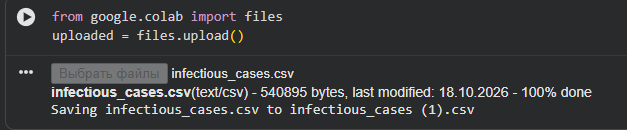

In [37]:
import pandas as pd
from sqlalchemy import create_engine, text

df = pd.read_csv('infectious_cases.csv')

engine = create_engine('sqlite:///pandemic.db')

df.to_sql('infectious_cases', engine, if_exists='replace', index=False)

print("Дані успішно імпортовані в таблицю infectious_cases!")

Дані успішно імпортовані в таблицю infectious_cases!


##Результат
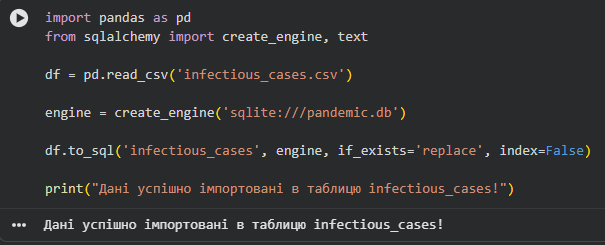

In [38]:
with engine.connect() as connection:
    query = text("SELECT * FROM infectious_cases LIMIT 10;")
    result = connection.execute(query)

    preview_df = pd.DataFrame(result.fetchall(), columns=result.keys())
    display(preview_df)

print(df.info())

,Entity,Code,Year,Number_yaws,polio_cases,cases_guinea_worm,Number_rabies,Number_malaria,Number_hiv,Number_tuberculosis,Number_smallpox,Number_cholera_cases
0,Afghanistan,AFG,1980,None,6160.0,0.0,None,None,None,None,None,None
1,Afghanistan,AFG,1981,None,5859.0,0.0,None,None,None,None,None,None
2,Afghanistan,AFG,1982,None,9730.0,0.0,None,None,None,None,None,None
3,Afghanistan,AFG,1983,None,13937.0,0.0,None,None,None,None,None,None
4,Afghanistan,AFG,1984,None,3864.0,0.0,None,None,None,None,None,None
5,Afghanistan,AFG,1985,None,13867.0,0.0,None,None,None,None,None,None
6,Afghanistan,AFG,1986,None,12901.0,0.0,None,None,None,None,None,None
7,Afghanistan,AFG,1987,None,4396.0,0.0,None,None,None,None,None,None
8,Afghanistan,AFG,1988,None,2149.0,0.0,None,None,None,None,None,None
9,Afghanistan,AFG,1989,None,385.0,0.0,None,None,None,None,None,None


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10521 entries, 0 to 10520
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Entity                10521 non-null  object 
 1   Code                  9393 non-null   object 
 2   Year                  10521 non-null  int64  
 3   Number_yaws           74 non-null     float64
 4   polio_cases           7610 non-null   float64
 5   cases_guinea_worm     8428 non-null   float64
 6   Number_rabies         6780 non-null   float64
 7   Number_malaria        6780 non-null   float64
 8   Number_hiv            6780 non-null   float64
 9   Number_tuberculosis   6780 non-null   float64
 10  Number_smallpox       104 non-null    float64
 11  Number_cholera_cases  2967 non-null   float64
dtypes: float64(9), int64(1), object(2)
memory usage: 986.5+ KB
None


##Результат
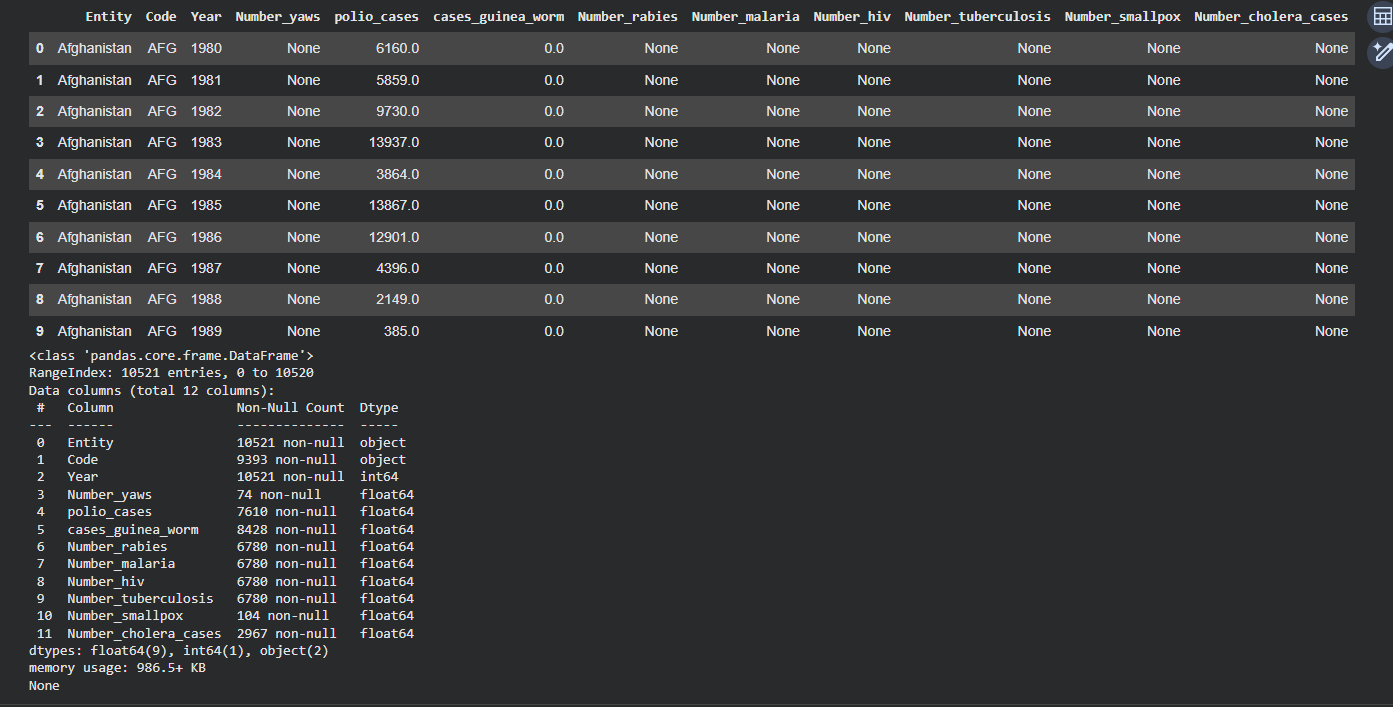

In [39]:
%config SqlMagic.style = '_DEPRECATED_DEFAULT'
%load_ext sql
%sql {engine.url}

The sql extension is already loaded. To reload it, use:
  %reload_ext sql


# 2. Нормалізація таблиці infectious_cases до 3-ї нормальної форми

In [40]:
%%sql

DROP TABLE IF EXISTS infectious_cases_normalized;
DROP TABLE IF EXISTS countries;

CREATE TABLE countries (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    Entity TEXT,
    Code TEXT
);

INSERT INTO countries (Entity, Code)
SELECT DISTINCT Entity, Code FROM infectious_cases;

CREATE TABLE infectious_cases_normalized AS
SELECT
    c.id AS country_id,
    i.Year,
    i.Number_yaws,
    i.polio_cases,
    i.cases_guinea_worm,
    i.Number_rabies,
    i.Number_malaria,
    i.Number_hiv,
    i.Number_tuberculosis,
    i.Number_smallpox,
    i.Number_cholera_cases
FROM infectious_cases i
JOIN countries c
  ON i.Entity = c.Entity
 AND (i.Code = c.Code OR (i.Code IS NULL AND c.Code IS NULL));

 * sqlite:///pandemic.db
Done.
Done.
Done.
245 rows affected.
Done.


[]

##Результат
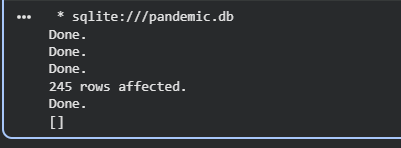

In [41]:
%%sql
SELECT * FROM countries LIMIT 5;

 * sqlite:///pandemic.db
Done.


id,Entity,Code
1,Afghanistan,AFG
2,Africa,None
3,African Region (WHO),None
4,Albania,ALB
5,Algeria,DZA


##Результат
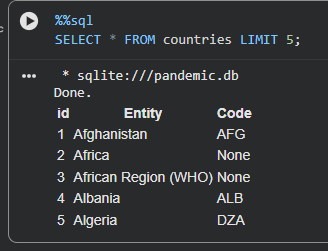

# 3. Aналіз данних

In [42]:
%%sql

SELECT
    c.Entity,
    c.Code,
    AVG(CAST(n.Number_rabies AS FLOAT)) AS avg_rabies,
    MIN(CAST(n.Number_rabies AS FLOAT)) AS min_rabies,
    MAX(CAST(n.Number_rabies AS FLOAT)) AS max_rabies,
    SUM(CAST(n.Number_rabies AS FLOAT)) AS sum_rabies
FROM infectious_cases_normalized n
JOIN countries c ON n.country_id = c.id
WHERE n.Number_rabies IS NOT NULL AND n.Number_rabies != ''
GROUP BY c.id, c.Entity, c.Code
ORDER BY avg_rabies DESC
LIMIT 10;

 * sqlite:///pandemic.db
Done.


Entity,Code,avg_rabies,min_rabies,max_rabies,sum_rabies
World,OWID_WRL,20192.370366666666,14075.508,24744.658,605771.111
Lower Middle Income (WB),None,15193.959383333333,10202.528,19182.795,455818.7815
South Asia (WB),None,11729.888753333333,7271.2754,15361.878,351896.6626
South-East Asia Region (WHO),None,11424.326893333335,6806.0127,15641.958,342729.8068
G20,None,10189.046003333333,6339.0796,13164.881,305671.3801
India,IND,8599.173279999999,5425.8726,11121.142,257975.1984
Sub-Saharan Africa (WB),None,4748.26809,4356.8184,5017.977,142448.0427
African Region (WHO),None,4649.702376666667,4283.073,4917.784,139491.0713
Low Income (WB),None,3568.10545,3014.617,3873.533,107043.1635
East Asia & Pacific (WB),None,3427.4611333333332,2009.9395,4591.0107,102823.834


##Результат
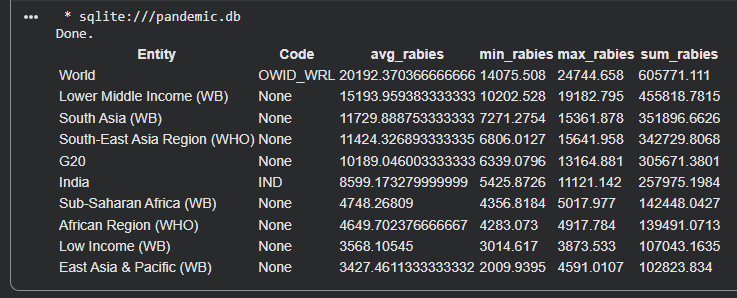

 # 4. Побудова колонки різниці в роках

In [43]:
%%sql

SELECT
    Year,
    DATE(Year || '-01-01') AS first_january,
    DATE('now') AS current_date_val,
    CAST(STRFTIME('%Y', 'now') AS INTEGER) - Year AS year_difference
FROM infectious_cases_normalized
LIMIT 10;

 * sqlite:///pandemic.db
Done.


Year,first_january,current_date_val,year_difference
1980,1980-01-01,2026-10-18,46
1981,1981-01-01,2026-10-18,45
1982,1982-01-01,2026-10-18,44
1983,1983-01-01,2026-10-18,43
1984,1984-01-01,2026-10-18,42
1985,1985-01-01,2026-10-18,41
1986,1986-01-01,2026-10-18,40
1987,1987-01-01,2026-10-18,39
1988,1988-01-01,2026-10-18,38
1989,1989-01-01,2026-10-18,37


##Результат
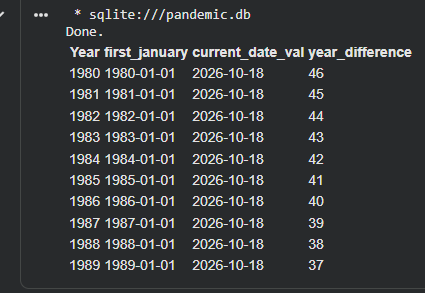

# 5. Побудова власної функції

In [44]:
import sqlite3
from datetime import datetime
from sqlalchemy import create_engine

engine = create_engine('sqlite:///pandemic.db')
conn = engine.raw_connection()

def year_diff(year):
    return datetime.now().year - int(year)

def calc_avg(cases, divisor):
    if cases is None or divisor is None or divisor == 0:
        return None
    return float(cases) / float(divisor)

conn.create_function("YEAR_DIFF", 1, year_diff)
conn.create_function("CALC_AVG", 2, calc_avg)

print("Власні функції успішно зареєстровані!")

Власні функції успішно зареєстровані!


##Результат
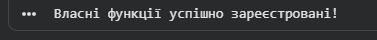

In [45]:
%%sql
SELECT
    Year,
    Number_rabies,
    CAST(STRFTIME('%Y', 'now') AS INTEGER) - Year AS calculated_year_diff,
    CAST(Number_rabies AS FLOAT) / 12 AS avg_per_month,
    CAST(Number_rabies AS FLOAT) / 4 AS avg_per_quarter,
    CAST(Number_rabies AS FLOAT) / 2 AS avg_per_half_year
FROM infectious_cases_normalized
WHERE Number_rabies IS NOT NULL AND Number_rabies != ''
LIMIT 10;

 * sqlite:///pandemic.db
Done.


Year,Number_rabies,calculated_year_diff,avg_per_month,avg_per_quarter,avg_per_half_year
1990,2.145772,36,0.17881433333333333,0.536443,1.072886
1991,2.3209748,35,0.19341456666666668,0.5802437,1.1604874
1995,3.126361,31,0.26053008333333333,0.78159025,1.5631805
1997,3.446122,29,0.2871768333333333,0.8615305,1.723061
1998,3.5570247,28,0.296418725,0.889256175,1.77851235
1999,3.607037,27,0.3005864166666667,0.90175925,1.8035185
2000,3.6362348,26,0.3030195666666667,0.9090587,1.8181174
2001,3.7118323,25,0.30931935833333335,0.927958075,1.85591615
2002,3.841707,24,0.32014225,0.96042675,1.9208535
2003,3.914814,23,0.3262345,0.9787035,1.957407


##Результат
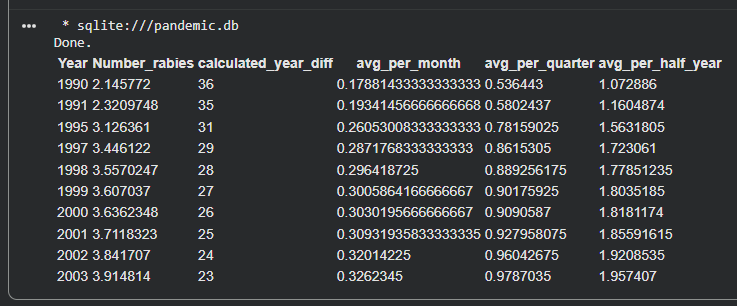